In [9]:
import numpy as np  
import matplotlib.pyplot as plt
import netCDF4 as nc
import torch
import os
import scipy as scp

import sys
sys.path.append("/home/mnex/Desktop/1DV_FD/LOTUS")
from mld_obs import met_start_day, read_lotus_temp, mld_sensor, bin_average

In [10]:
OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/3_Lotus_realistic/output'
with np.load(os.path.join(OUTPUT_FOLDER, 'lotus_forcing.npz')) as forcing:
    ua  = forcing['ua']
    Qns = forcing['Q_ns']
    Qsw = forcing['Q_sw']
    dt  = float(forcing['dt'])

time = np.arange(ua.shape[1]) * dt / 86400          # days since 13 May 1982

def plot_with_envelope(ax, time, var_m, var_std, color=None, label=None):
    ax.fill_between(time, var_m - var_std, var_m + var_std, color=color, alpha=0.3, lw=0,
                    label=r'$\pm 1$ std' if label else None)
    ax.plot(time, var_m, color=color, lw=1.0, label=label)

def daily_mean(var, dt):
    n_day = int(round(86400 / dt))
    n_full = (len(var) // n_day) * n_day
    return var[:n_full].reshape(-1, n_day).mean(axis=1), (np.arange(n_full // n_day) + 0.5)


# Wind and heat fluxes forcing

(0.0, 159.97916666666666)

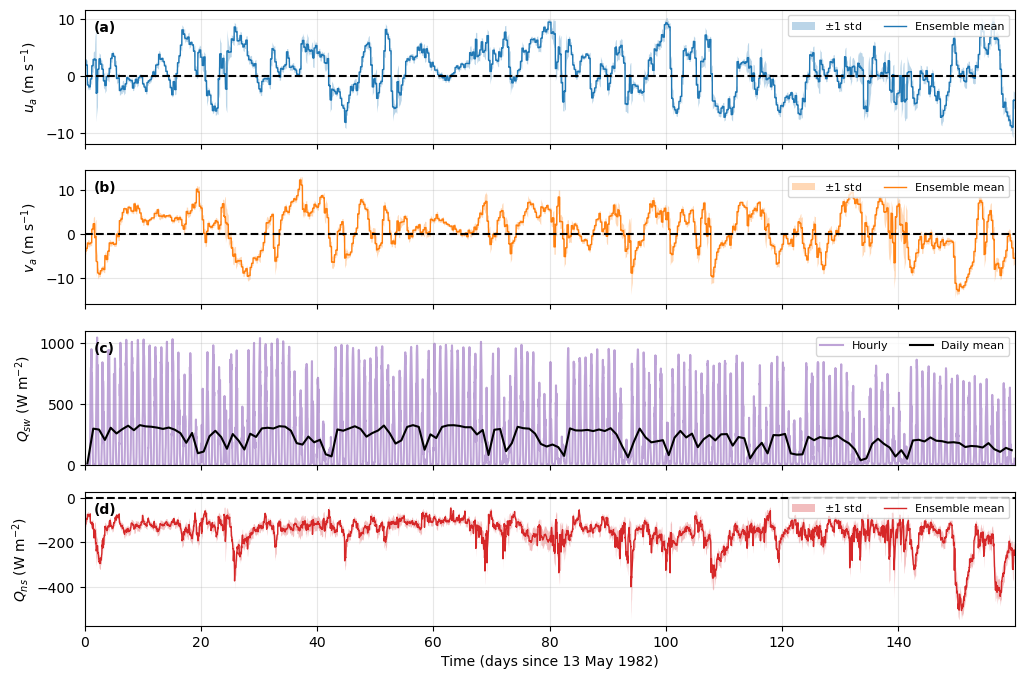

In [11]:
fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

# Zonal wind
plot_with_envelope(ax[0], time, ua.real.mean(0), ua.real.std(0), color='C0', label='Ensemble mean')
ax[0].set_ylabel(r'$u_a$ (m s$^{-1}$)')

# Meridional wind
plot_with_envelope(ax[1], time, ua.imag.mean(0), ua.imag.std(0), color='C1', label='Ensemble mean')
ax[1].set_ylabel(r'$v_a$ (m s$^{-1}$)')

# Net shortwave (deterministic) + daily mean
Qsw_day, t_day = daily_mean(Qsw, dt)
ax[2].plot(time, Qsw, color='C4', alpha=0.6, label='Hourly')
ax[2].plot(t_day, Qsw_day, color='k', label='Daily mean')
ax[2].set_ylabel(r'$Q_{sw}$ (W m$^{-2}$)')
ax[2].set_ylim(bottom=0)

# Non-solar heat flux (positive into the ocean)
plot_with_envelope(ax[3], time, Qns.mean(0), Qns.std(0), color='C3', label='Ensemble mean')
ax[3].set_ylabel(r'$Q_{ns}$ (W m$^{-2}$)')
ax[3].set_xlabel('Time (days since 13 May 1982)')

for a, letter in zip(ax, 'abcd'):
    a.grid(alpha=0.3)
    a.text(0.01, 0.92, f'({letter})', transform=a.transAxes, fontweight = 'bold', va='top')
    a.legend(loc='upper right', fontsize=8, ncol=2)
    
for a in (ax[0], ax[1], ax[3]):
    a.axhline(0, color='k', ls='--')
ax[-1].set_xlim(time[0], time[-1])

# MLD DIagnostic

0 profiles still incomplete after filling


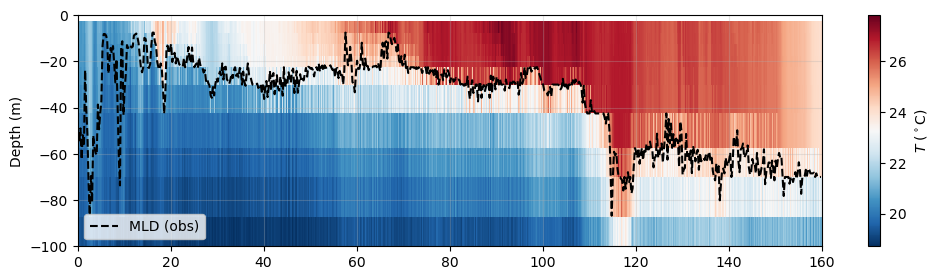

In [12]:
MET_FILE  = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusmet.epic'
TEMP_FILE = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusnstemp.epic'
N_DAYS    = 160
BIN_HOURS = 6

# --- Observations ---
t0 = met_start_day(MET_FILE)
t_obs, depth_s, T_obs = read_lotus_temp(TEMP_FILE, t0, N_DAYS)
mld_obs = mld_sensor(T_obs, depth_s)

edges = np.arange(0.0, N_DAYS + 1e-9, BIN_HOURS / 24)
t_bin = 0.5 * (edges[1:] + edges[:-1])
mld_obs_bin = bin_average(t_obs, mld_obs, edges)
 
fig, ax = plt.subplots(1, 1, figsize=(12, 3))

pc = ax.pcolormesh(t_obs, -depth_s, T_obs.T, cmap='RdBu_r', shading='nearest')
ax.plot(t_bin, -mld_obs_bin, 'k--', label='MLD (obs)')
ax.set_ylabel('Depth (m)')
ax.set_ylim(-depth_s[-1], 0)
fig.colorbar(pc, ax=ax, label=r'$T$ ($^\circ$C)')
ax.legend(loc='lower left')
ax.grid(alpha=0.3)

In [13]:
def plot_MLD_model(model_name, ne, label = None, color = 'C0', window_ave = 24):
    OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/3_Lotus_realistic/output/'
    file_name = OUTPUT_FOLDER + f'lotus_stratif_{model_name}_ne{ne}.nc'
    
    with nc.Dataset(file_name) as data:
        t   = data['time'][:]
        mld_m  = -data[f'mld_mean'][:]
        mld_v  = data[f'mld_var'][:]
    
    # --- Window averaging ---
    nt = mld_m.shape[0]
    dt = t[1] - t[0]
    n_win = nt // window_ave
    mld_m_ave = mld_m[:n_win * window_ave].reshape(n_win, window_ave).mean(axis=1)
    mld_v_ave = mld_v[:n_win * window_ave].reshape(n_win, window_ave).mean(axis=1)
    t_ave = (np.arange(n_win) + 0.5) * window_ave * dt / 86400
    
    plt.plot(t_ave, mld_m_ave, label = label, color = color)
    plt.fill_between(t_ave,
                     mld_m_ave + mld_v_ave**0.5, 
                     mld_m_ave - mld_v_ave**0.5, 
                     color = color, alpha = 0.2)

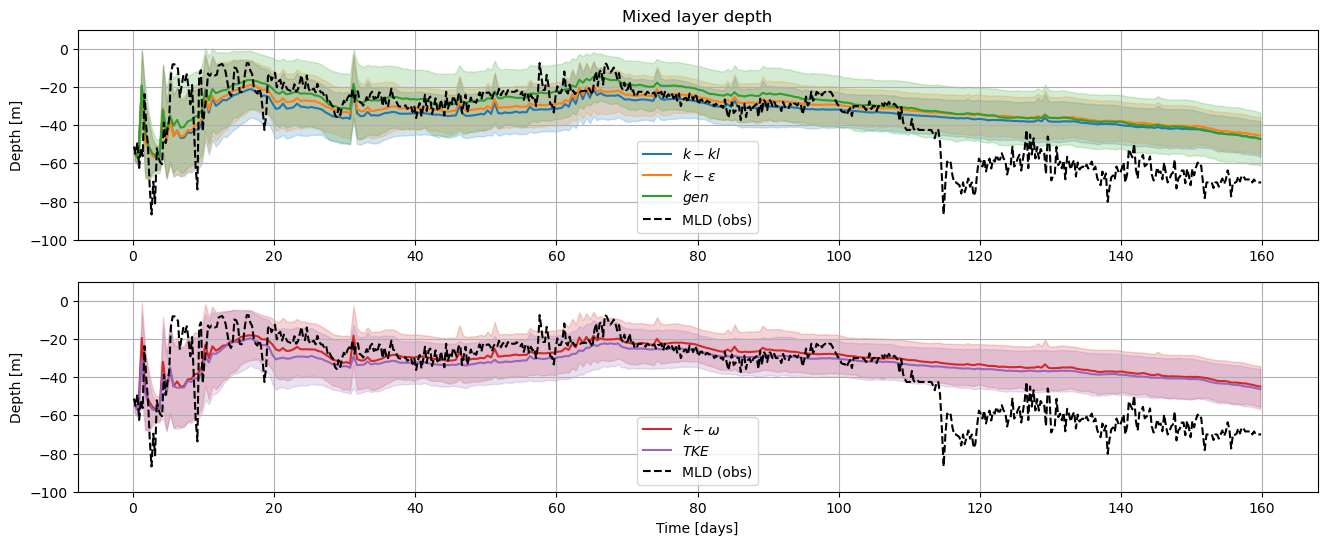

In [14]:
plt.figure(figsize=(16, 6))

plt.subplot(211)
plt.title('Mixed layer depth')
plt.ylabel('Depth [m]')

NENS = 1000

# Model
plot_MLD_model('k-kl',      NENS, r'$k-kl$',          'C0')
plot_MLD_model('k-epsilon', NENS, r'$k-\varepsilon$', 'C1')
plot_MLD_model('k-omega',   NENS, r'$gen$',           'C2')

# REF
plt.plot(t_bin, -mld_obs_bin, 'k--', label='MLD (obs)')
plt.ylim(-100, 10)
plt.legend()
plt.grid()

plt.subplot(212)
plt.xlabel('Time [days]')
plt.ylabel('Depth [m]')

plot_MLD_model('gen',   NENS, r'$k-\omega$', 'C3')
plot_MLD_model('tke',       NENS, r'$TKE$',  'C4')

# REF
plt.plot(t_bin, -mld_obs_bin, 'k--', label='MLD (obs)')
plt.ylim(-100, 10)
plt.legend()
plt.grid()

## To explaint the gap after 110 days

(0.0, 160.0)

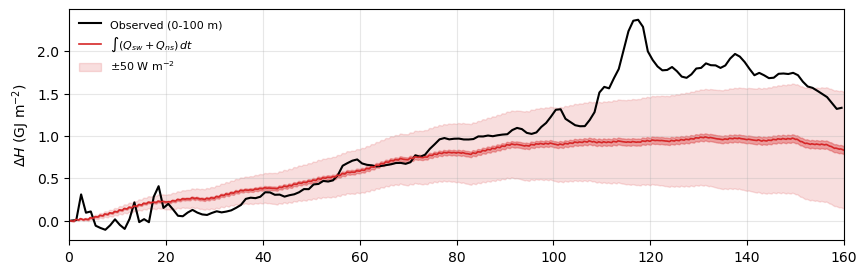

In [30]:
FLUX_ERR  = 50.0                     # W m-2, bulk-flux accuracy (check Deser et al. 1983)
N_DAYS    = 160

def epic_days(f):
    return f['time'][:].astype(float) + f['time2'][:].astype(float) / 86400e3

def daily_mean(t, x, n_days):
    day = np.floor(t).astype(int)
    out = np.full(n_days, np.nan)
    for d in range(n_days):
        sel = (day == d) & np.isfinite(x)
        if sel.any():
            out[d] = x[sel].mean()
    return np.arange(n_days) + 0.5, out

# --- Observed temperature ---
with nc.Dataset(MET_FILE) as f:
    f.set_auto_mask(False)
    t0 = epic_days(f)[0]
    
with nc.Dataset(TEMP_FILE) as f:
    f.set_auto_mask(False)
    t_obs = epic_days(f) - t0
    depth = np.abs(f['depth'][:])
    temp  = f['temp'][:, :, 0, 0]

order = np.argsort(depth)
depth, temp = depth[order], temp[:, order]
temp[np.abs(temp) > 1e30] = np.nan
keep = (t_obs >= 0) & (t_obs <= N_DAYS)
t_obs, temp = t_obs[keep], temp[keep]

# --- Heat content 0-100 m ---
RHO_CP = 1000.0 * 3985.0
z_int = np.concatenate(([0.0], depth))
T_int = np.concatenate((temp[:, :1], temp), axis=1)
H_obs = RHO_CP * np.trapezoid(T_int, z_int, axis=1)                 # J m-2 (NaN if a sensor is missing)
t_day, H_obs_d = daily_mean(t_obs, H_obs, N_DAYS)
dH_obs = H_obs_d - H_obs_d[0]

# --- Cumulative surface flux from the saved forcing ---
with np.load(os.path.join(OUTPUT_FOLDER, 'lotus_forcing.npz')) as fz:
    Qns, Qsw, dt = fz['Q_ns'], fz['Q_sw'], float(fz['dt'])
t_f   = np.arange(Qns.shape[1]) * dt / 86400
Q_net = Qns + Qsw[None, :]                                       # (ne, nt) W m-2
dH_f  = np.cumsum(Q_net, axis=1) * dt                            # J m-2, per member
dH_f_m, dH_f_s = dH_f.mean(0), dH_f.std(0)
dH_err = FLUX_ERR * t_f * 86400                                  # +- integrated flux error

# --- Figure ---
GJ = 1e9
fig, ax = plt.subplots(1, 1, figsize=(10, 3))

ax.plot(t_day, dH_obs / GJ, 'k', lw=1.5, label='Observed (0-100 m)')
ax.plot(t_f, dH_f_m / GJ, 'C3', lw=1.2, label=r'$\int (Q_{sw}+Q_{ns})\,dt$')
ax.fill_between(t_f, (dH_f_m - dH_err) / GJ, (dH_f_m + dH_err) / GJ,
                   color='C3', alpha=0.15, label=rf'$\pm${FLUX_ERR:.0f} W m$^{{-2}}$')
ax.fill_between(t_f, (dH_f_m - dH_f_s) / GJ, (dH_f_m + dH_f_s) / GJ, color='C3', alpha=0.35)
ax.set_ylabel(r'$\Delta H$ (GJ m$^{-2}$)')
ax.legend(loc='upper left', fontsize=8, frameon=False)

ax.grid(alpha=0.3)
ax.set_xlim(0, N_DAYS)